# Examples

Run top to bottom. Inputs are in `../data`; figures are displayed inline.
Input checksums can be verified with `python scripts/render_figures.py --all`.

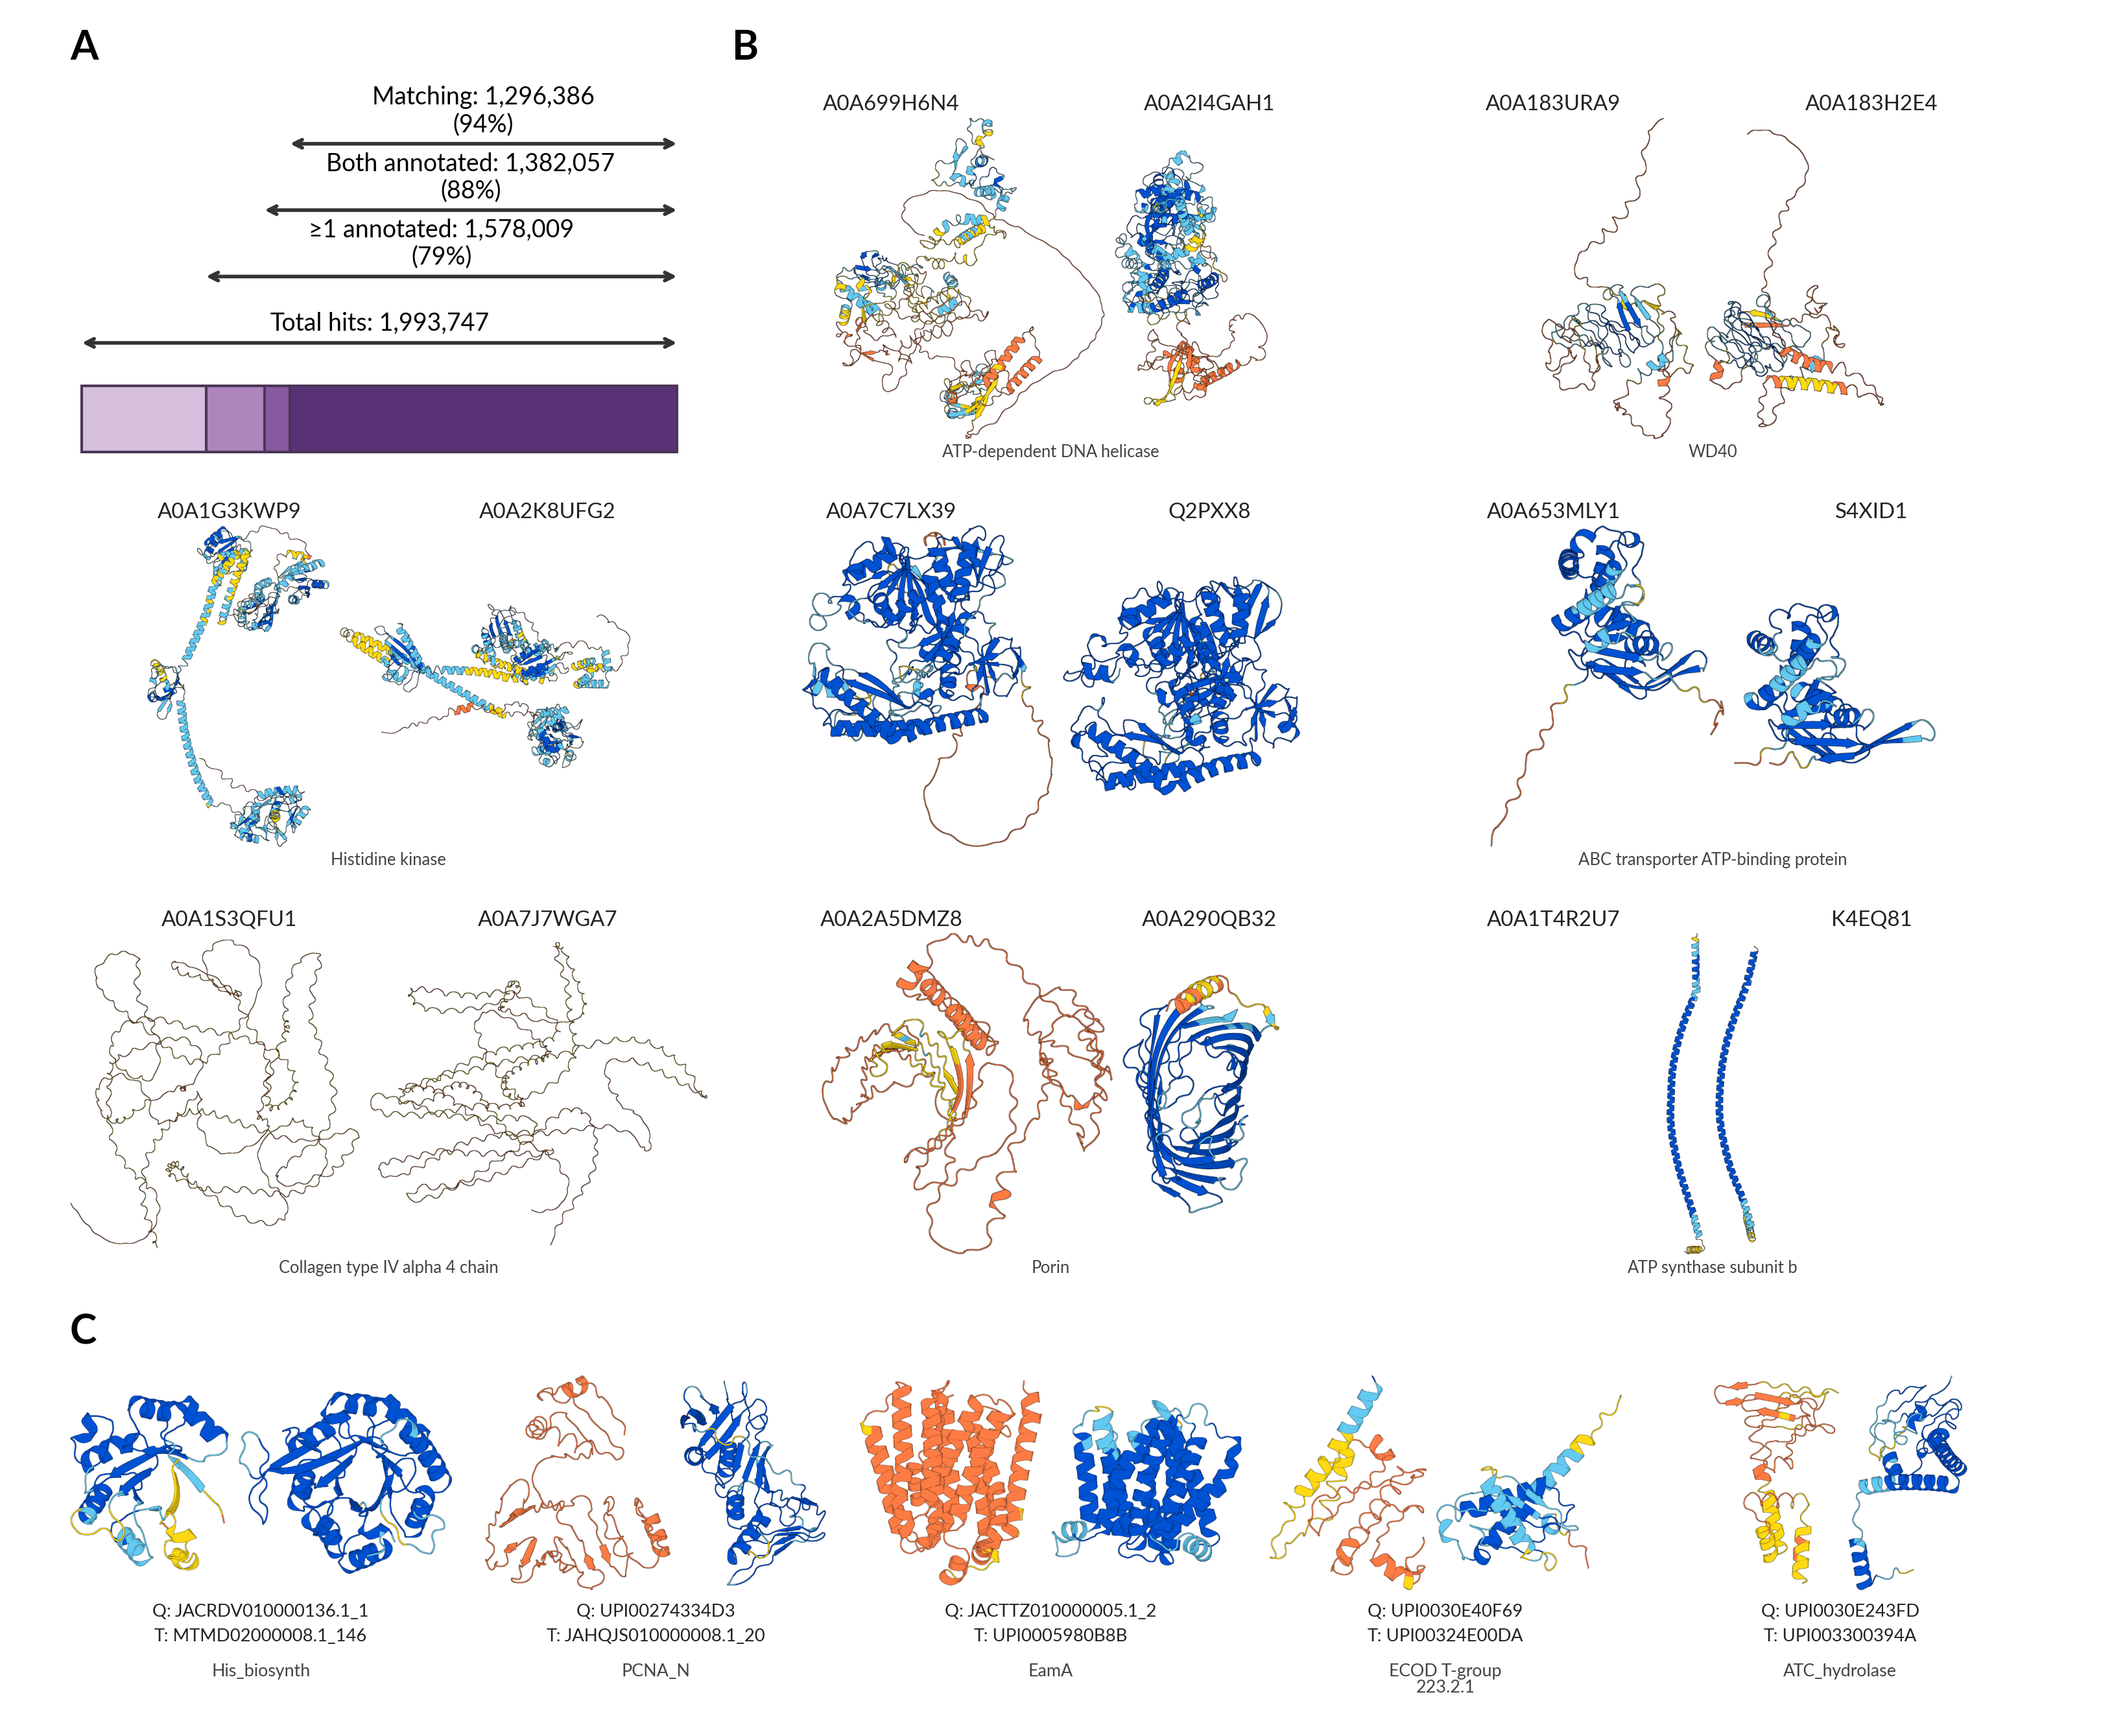

In [2]:
from io import BytesIO
from IPython.display import display, Image as InlineImage
from pathlib import Path
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path('..').resolve()  # Run from notebooks.

# Physical paper dimensions, in inches; typography is specified at this size.
PAPER_STYLE = {'font': 'Lato', 'font_size': 7.0, 'tick_size': 6.5,
               'legend_size': 6.3, 'panel_size': 10.0, 'dpi': 450,
               'line_width': 1.05, 'marker_size': 2.8}

def paper_rc():
    mpl.rcParams.update({
        'font.family': PAPER_STYLE['font'], 'font.size': PAPER_STYLE['font_size'],
        'font.weight': 'normal', 'axes.labelweight': 'normal',
        'axes.labelsize': PAPER_STYLE['font_size'], 'axes.labelpad': 2.5,
        'xtick.labelsize': PAPER_STYLE['tick_size'],
        'ytick.labelsize': PAPER_STYLE['tick_size'],
        'legend.fontsize': PAPER_STYLE['legend_size'], 'legend.frameon': False,
        'legend.handlelength': 1.5, 'legend.labelspacing': .35,
        'axes.spines.top': False, 'axes.spines.right': False,
        'axes.linewidth': .65, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
        'xtick.major.width': .6, 'ytick.major.width': .6,
        'xtick.major.pad': 2, 'ytick.major.pad': 2,
        'grid.linewidth': .45, 'grid.color': '#dedde1',
        'mathtext.fontset': 'custom', 'mathtext.rm': 'Lato',
        'mathtext.it': 'Lato:italic', 'mathtext.bf': 'Lato:bold',
        'mathtext.cal': 'Lato', 'mathtext.sf': 'Lato', 'mathtext.tt': 'Lato',
        'path.simplify': False, 'savefig.bbox': None,
    })


def paper_letter(figure, axis, letter, *, dx=-.20, dy=.07):
    # Offsets are physical inches, independent of the subplot aspect ratio.
    bounds = axis.get_position(original=True)
    width, height = figure.get_size_inches()
    return figure.text(bounds.x0 + dx/width, bounds.y1 + dy/height, letter,
                       ha='left', va='bottom', fontsize=PAPER_STYLE['panel_size'],
                       fontweight='bold')


TABLES = ROOT/'data/plot_tables/figure4/foldseek_thresholds'
# A and the eight AFDB pairs share a regular three-column mosaic.
LAYOUT = {'size': (7.2, 5.95),
          'gallery_left': .24/7.2, 'gallery_right': 6.96/7.2,
          'B_bottom': 1.55/5.95, 'B_top': 5.65/5.95,
          'C_bottom': .12/5.95, 'C_top': 1.25/5.95,
          'id_size': 5.3, 'partner_gap_inches': .035}
paper_rc()
fig = plt.figure(figsize=LAYOUT['size'], dpi=150)
B_grid = fig.add_gridspec(3, 3, left=LAYOUT['gallery_left'], right=LAYOUT['gallery_right'],
                         bottom=LAYOUT['B_bottom'], top=LAYOUT['B_top'],
                         wspace=.04, hspace=.07)
A = fig.add_axes(B_grid[0,0].get_position(fig))
C_grid = fig.add_gridspec(1, 5, left=LAYOUT['gallery_left'],
                          right=LAYOUT['gallery_right'],
                          bottom=LAYOUT['C_bottom'], top=LAYOUT['C_top'],
                          wspace=.035)

cascade = pd.read_csv(TABLES/'afdb_cascade.tsv',
                      sep='\t')
required = ['all_hits','either_annotated','both_annotated',
            'same_family_or_clan_or_interpro']
counts = cascade.set_index('stage').loc[required,'count'].astype(int)
total,either,both,matched = counts.to_numpy()
colors = ['#d6bfdc','#ae86bb','#8759a0','#593276']
segments = [total-either,either-both,both-matched,matched]
left = 0
for amount,color in zip(segments,colors):
    A.barh(0,amount/total,height=.27,left=left,color=color,
           edgecolor='#4b3657',linewidth=.65)
    left += amount/total
stages = [('Total hits',total,0,None),
          ('≥1 annotated',either,(total-either)/total,total),
          ('Both annotated',both,(total-both)/total,either),
          ('Matching',matched,(total-matched)/total,both)]
for index,(label,value,boundary,denominator) in enumerate(stages):
    arrow_y = .31 + index*.27
    A.annotate('',xy=(boundary,arrow_y),xytext=(1,arrow_y),
               arrowprops=dict(arrowstyle='<->',color='#333333',lw=.9,
                               shrinkA=0,shrinkB=0,mutation_scale=5))
    text = f'{label}: {value:,}'
    if denominator is not None:
        text += f'\n({100*value/denominator:.0f}%)'
    A.text((boundary+1)/2,arrow_y+.032,text,ha='center',va='bottom',fontsize=6.0)
A.set(xlim=(-.02,1.05),ylim=(-.20,1.35))
A.axis('off')


import csv
import textwrap


EXAMPLE_DATA = ROOT/'data/plot_tables/figure4'

def read_selection(dataset):
    with (EXAMPLE_DATA/'selected_rescue_examples.tsv').open() as handle:
        return [row for row in csv.DictReader(handle, delimiter='\t')
                if row['dataset'] == dataset and row['selection_status'] == 'selected']

def pair_images(row):
    name = '__'.join(row[role].replace('|', '_') for role in ('query', 'target'))
    for role in ('query', 'target'):
        with Image.open(EXAMPLE_DATA/'shared_orientation'/name/f'{role}.png') as source:
            image = source.convert('RGBA')
        yield image.crop(image.getchannel('A').getbbox())

def draw_gallery(fig, dataset):
    rows = read_selection(dataset)
    fw, fh = fig.get_size_inches()
    for index, row in enumerate(rows):
        if dataset == 'afdb_clusters':
            slot = B_grid[(index+1) // 3, (index+1) % 3].get_position(fig)
        else:
            slot = C_grid[0, index].get_position(fig)
        x, y, width, height = slot.x0 * fw, slot.y0 * fh, slot.width * fw, slot.height * fh
        images = list(pair_images(row))
        gap = LAYOUT['partner_gap_inches']
        footer, header = ((.10, .105) if dataset == 'afdb_clusters' else (.38, .015))
        image_height = height - footer - header
        factor = min((width - gap) / sum(im.width for im in images),
                     image_height / max(im.height for im in images))
        total = sum(im.width * factor for im in images) + gap
        left = x + (width - total) / 2
        for side, (role, image) in enumerate(zip(('query', 'target'), images)):
            w, h = image.width * factor, image.height * factor
            rect = [left/fw, (y + footer + (image_height-h)/2)/fh, w/fw, h/fh]
            ax = fig.add_axes(rect)
            ax.imshow(image, interpolation='antialiased')
            ax.set_axis_off()
            if dataset == 'afdb_clusters':
                fig.text((x + (side+.5)*width/2)/fw, (y+height-.025)/fh,
                         row[role].split('|')[-1], ha='center', va='top',
                         fontsize=LAYOUT['id_size'], color='#222222')
            left += w + gap
        if dataset == 'archaeal':
            # Both models remain side by side; full accessions use the slot width.
            for side, role in enumerate(('query', 'target')):
                fig.text((x+width/2)/fw, (y+.335-side*.085)/fh,
                         ('Q: ' if side == 0 else 'T: ') + row[role].split('|')[-1],
                         ha='center', va='top', fontsize=4.4, color='#222222')
        annotation = row['label']
        if annotation == 'Shared protein annotation':
            annotation = ''
        if annotation and dataset == 'afdb_clusters':
            fig.text((x+width/2)/fw, (y+.055)/fh, annotation,
                     ha='center', va='center', fontsize=4.1, color='#444444')
        elif annotation:
            fig.text((x+width/2)/fw, (y+.13)/fh, textwrap.fill(annotation, width=16),
                     ha='center', va='top', fontsize=4.3, color='#444444', linespacing=1.0)
draw_gallery(fig, 'afdb_clusters')
draw_gallery(fig, 'archaeal')
paper_letter(fig, A, 'A', dx=0)
fig.text(B_grid[0,1].get_position(fig).x0, LAYOUT['B_top']+.07/LAYOUT['size'][1], 'B', ha='left', va='bottom',
         fontsize=PAPER_STYLE['panel_size'], fontweight='bold')
fig.text(LAYOUT['gallery_left'], LAYOUT['C_top']+.07/LAYOUT['size'][1], 'C', ha='left', va='bottom',
         fontsize=PAPER_STYLE['panel_size'], fontweight='bold')
for image_axis in fig.axes:
    if not image_axis.axison:
        image_axis.set_xticks([])
        image_axis.set_yticks([])
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=PAPER_STYLE['dpi'],facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))